<a href="https://colab.research.google.com/github/equipe31ccpj/Sprint4-Modelagem-Linear-para-Aprendizado-de-M-quina/blob/main/Challenge_Sprint_IV_Modelagem_Linear.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Challenge Sprint 4 - Inteligência Artificial e Machine Learning

**Membro:** [Maria Eduarda Rocha Benjamim] - RM: [570554]


**Membro:** [Pedro Henrique Neves] - RM: [571382]  


**Membro:** [Akin Alexandre Mendes Martins] - RM: [572553]  




---


## 01) Análise do Dataset
Abaixo, realizamos o carregamento dos dados diretamente do repositório remoto do GitHub (via link Raw), tratamos a variável-alvo e plotamos a matriz de correlação para avaliar a relação entre as features de produção de energia renovável.

In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score
from sklearn.metrics import classification_report

Dataset carregado!
Formato do DataFrame original: (1000, 11)
Encoding concluído. Mapeamento das classes: {'High': np.int64(0), 'Low': np.int64(1), 'Medium': np.int64(2)}


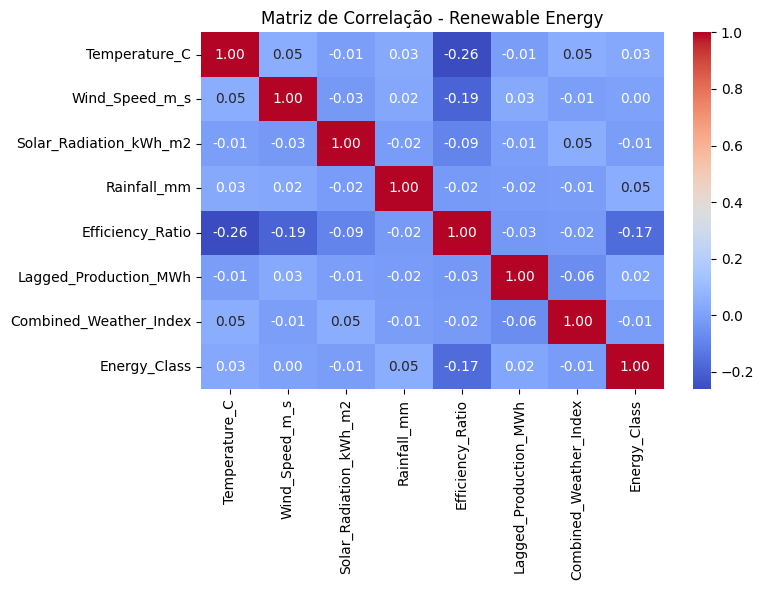

In [14]:
# Carregamento do dataset (GitHub do grupo)
url_raw = "Renewable_Energy_Data.csv"

# Carregando os dados de forma reprodutível
df = pd.read_csv('https://raw.githubusercontent.com/equipe31ccpj/Sprint4-Modelagem-Linear-para-Aprendizado-de-M-quina/refs/heads/main/Renewable_Energy_Data.csv')
print("Dataset carregado!")
print("Formato do DataFrame original:", df.shape)

# b) Encoding da variável-alvo (Energy_Class)
label_encoder = LabelEncoder()
df['Energy_Class'] = label_encoder.fit_transform(df['Energy_Class'])
print("Encoding concluído. Mapeamento das classes:",
      dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

# c) Matriz de correlação
correlation_matrix = df.corr(numeric_only=True)

# Plotagem da Matriz de Correlação
# Salvando a matriz de correlação como imagem para o repositório
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriz de Correlação - Renewable Energy")
plt.tight_layout()
plt.savefig("matriz_correlacao.png", dpi=150)
plt.show()

#### Nota sobre o Pré-Processamento e Engenharia de Features

Em cada cenário, **após a divisão treino/teste**, aplicamos o `StandardScaler` do *scikit-learn* para realizar a **padronização de escala (Z-score)** das variáveis preditoras. O scaler é ajustado (`fit`) **apenas nos dados de treino** e depois aplicado (`transform`) ao teste, evitando *data leakage* (vazamento de informação do teste para o treino). Este passo é obrigatório e crucial para algoritmos lineares como a Regressão Logística.

Como o modelo calcula a fronteira de decisão baseada em coeficientes matemáticos, variáveis com ordens de grandeza muito diferentes (ex: demandas na casa dos milhares vs frações de KW) distorceriam os pesos do modelo, impedindo a convergência correta do algoritmo e enviesando os resultados.

### Justificativa Técnica sobre a Seleção de Features

Ao analisar a matriz de correlação gerada, percebe-se que as variáveis preditoras numéricas (`Temperature_C`, `Wind_Speed_m_s`, `Solar_Radiation_kWh_m2`, `Rainfall_mm`, `Efficiency_Ratio`, `Lagged_Production_MWh` e `Combined_Weather_Index`) têm correlação baixa entre si. O maior valor absoluto é da ordem de 0,26, entre `Temperature_C` e `Efficiency_Ratio`. Isso indica que não há multicolinearidade. Cada uma dessas variáveis contribui de forma quase independente para o sistema.

A correlação de cada uma dessas variáveis com `Energy_Class` também é baixa. O valor mais alto é da ordem de −0,17, com `Efficiency_Ratio`. Isso não é motivo suficiente para excluí-las. O coeficiente de Pearson mede apenas relações lineares entre pares de variáveis. `Energy_Class` é uma variável nominal que foi codificada em ordem alfabética (High=0, Low=1, Medium=2), então a correlação com o alvo é apenas indicativa.

Além disso, as variáveis categóricas (`Region`, `Energy_Source`, `Season`) não estão na matriz de correlação, mas entram no modelo por meio do One-Hot Encoding.

Por isso, é melhor usar todas as variáveis disponíveis no modelo de classificação. Modelos lineares funcionam bem quando combinam vários fatores independentes para definir sua fronteira de decisão. O número de variáveis é pequeno em relação às 1000 observações, então não há risco de maldição da dimensionalidade. A exclusão de variáveis só faria sentido se houvesse colinearidade muito forte, por exemplo, acima de 0,85. Nesse caso, uma das variáveis seria redundante. Isso não acontece aqui, conforme mostrado na matriz de correlação.

## 02) Definição e Aplicação do Modelo

* **Modelo Selecionado:** Regressão Logística (`LogisticRegression`).
* **Justificativa de Linearidade:** A Regressão Logística é considerada um modelo linear porque a sua **fronteira de decisão (decision boundary) é uma combinação linear** das variáveis de entrada. O algoritmo encontra pesos (coeficientes) para cada variável que definem uma linha reta (em 2D), um plano (em 3D) ou um hiperplano reto (em dimensões maiores) para separar as classes de consumo/geração energética.


In [15]:
# Preparação dos dados e codificação automática de todas as variáveis categóricas (One-Hot Encoding)
X = df.drop(columns=['Energy_Class'])
y = df['Energy_Class']

# Ao omitir o parâmetro 'columns', o pandas converte automaticamente todas as colunas de texto (Region, Energy_Source e Season)
X_encoded = pd.get_dummies(X, drop_first=True)

# Padronização (essencial para modelos lineares): feita dentro de cada cenário, APÓS o split,
# ajustando o StandardScaler somente no treino para evitar data leakage

In [16]:
X_train1, X_test1, y_train1, y_test1 = train_test_split(X_encoded, y, test_size=0.40, random_state=42, stratify=y)

# Padronização ajustada apenas no treino
scaler1 = StandardScaler()
X_train1 = scaler1.fit_transform(X_train1)
X_test1 = scaler1.transform(X_test1)

# Treinamento do Cenário 1
model1 = LogisticRegression(max_iter=1000, random_state=42)
model1.fit(X_train1, y_train1)
y_pred1 = model1.predict(X_test1)

print("Modelo do Cenário 1 (60% Treino / 40% Teste) treinado com sucesso!")

Modelo do Cenário 1 (60% Treino / 40% Teste) treinado com sucesso!


In [17]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(X_encoded, y, test_size=0.15, random_state=42, stratify=y)

# Padronização ajustada apenas no treino
scaler2 = StandardScaler()
X_train2 = scaler2.fit_transform(X_train2)
X_test2 = scaler2.transform(X_test2)

# Treinamento do Cenário 2
model2 = LogisticRegression(max_iter=1000, random_state=42)
model2.fit(X_train2, y_train2)
y_pred2 = model2.predict(X_test2)

print("Modelo do Cenário 2 (85% Treino / 15% Teste) treinado com sucesso!")

Modelo do Cenário 2 (85% Treino / 15% Teste) treinado com sucesso!


## 03) Avaliação da Performance
Abaixo, geramos as matrizes de confusão e calculamos as métricas de Acurácia, Precisão e Recall para comparar os dois cenários de divisão dos dados.


In [18]:
def avaliar_modelo(y_true, y_pred, titulo, arquivo=None):
    cm = confusion_matrix(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec = recall_score(y_true, y_pred, average='macro', zero_division=0)

    # Plot da matriz de confusão
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
    plt.title(f"Matriz de Confusão: {titulo}")
    plt.ylabel("Real")
    plt.xlabel("Predito")
    plt.tight_layout()
    if arquivo:
        plt.savefig(arquivo, dpi=150)  # salva a imagem para o repositório
    plt.show()

    print(f"Métricas para {titulo}:")
    print(f"-> Acurácia: {acc:.4f}")
    print(f"-> Precisão: {prec:.4f}")
    print(f"-> Recall:   {rec:.4f}\n")

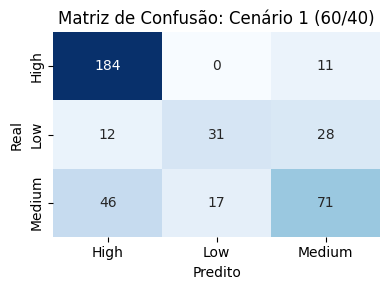

Métricas para Cenário 1 (60/40):
-> Acurácia: 0.7150
-> Precisão: 0.6839
-> Recall:   0.6367



In [19]:
# Avaliação do Cenário 1 (60% Treino / 40% Teste)
avaliar_modelo(y_test1, y_pred1, "Cenário 1 (60/40)", "matriz_confusao_cenario1.png")

In [20]:
print("CENÁRIO 1 (60/40) - Relatório de classificação")
print(classification_report(y_test1, y_pred1, target_names=label_encoder.classes_, zero_division=0))

CENÁRIO 1 (60/40) - Relatório de classificação
              precision    recall  f1-score   support

        High       0.76      0.94      0.84       195
         Low       0.65      0.44      0.52        71
      Medium       0.65      0.53      0.58       134

    accuracy                           0.71       400
   macro avg       0.68      0.64      0.65       400
weighted avg       0.70      0.71      0.70       400



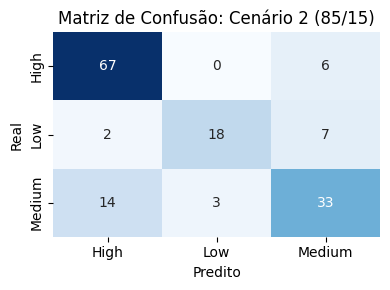

Métricas para Cenário 2 (85/15):
-> Acurácia: 0.7867
-> Precisão: 0.7939
-> Recall:   0.7482



In [21]:
# Avaliação do Cenário 2 (85% Treino / 15% Teste)
avaliar_modelo(y_test2, y_pred2, "Cenário 2 (85/15)", "matriz_confusao_cenario2.png")

In [22]:
print("CENÁRIO 2 (85/15) - Relatório de classificação")
print(classification_report(y_test2, y_pred2, target_names=label_encoder.classes_, zero_division=0))

CENÁRIO 2 (85/15) - Relatório de classificação
              precision    recall  f1-score   support

        High       0.81      0.92      0.86        73
         Low       0.86      0.67      0.75        27
      Medium       0.72      0.66      0.69        50

    accuracy                           0.79       150
   macro avg       0.79      0.75      0.77       150
weighted avg       0.79      0.79      0.78       150



In [23]:
# Criando o dicionário de resultados com as métricas reais dos dois cenários
resultados = {
    'Cenário 1 (60/40)': {
        'Acurácia': accuracy_score(y_test1, y_pred1),
        'Precisão': precision_score(y_test1, y_pred1, average='macro', zero_division=0),
        'Recall': recall_score(y_test1, y_pred1, average='macro', zero_division=0),
        'Tamanho do teste': len(y_test1)
    },
    'Cenário 2 (85/15)': {
        'Acurácia': accuracy_score(y_test2, y_pred2),
        'Precisão': precision_score(y_test2, y_pred2, average='macro', zero_division=0),
        'Recall': recall_score(y_test2, y_pred2, average='macro', zero_division=0),
        'Tamanho do teste': len(y_test2)
    }
}

# d) Tabela comparativa dos dois cenários
comparacao = pd.DataFrame(resultados).T
comparacao['Tamanho do teste'] = comparacao['Tamanho do teste'].astype(int)
comparacao = comparacao.round(4)

# Diferença entre os cenários (Cenário 2 - Cenário 1)
dif = (comparacao.iloc[1, :3] - comparacao.iloc[0, :3]).round(4)
comparacao.loc['Diferença (C2 - C1)'] = list(dif) + ['']

comparacao.to_csv('metricas_cenarios.csv')
comparacao

,Acurácia,Precisão,Recall,Tamanho do teste
Cenário 1 (60/40),0.7150,0.6839,0.6367,400
Cenário 2 (85/15),0.7867,0.7939,0.7482,150
Diferença (C2 - C1),0.0717,0.1100,0.1115,


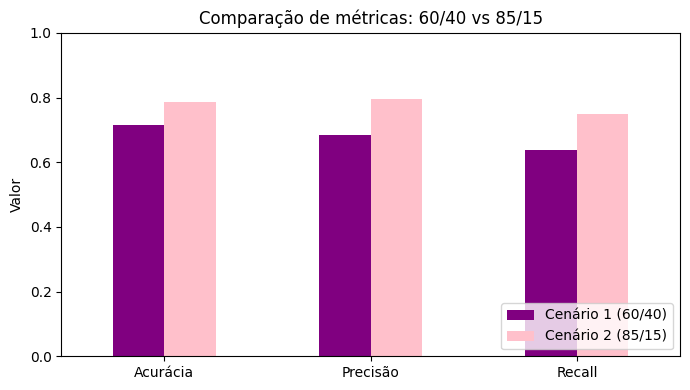

In [24]:
# Defina as cores desejadas para cada cenário (roxo e rosa)
cores = ['purple', 'pink']

comparacao.iloc[:2, :3].astype(float).T.plot(kind='bar', figsize=(7, 4), rot=0, color=cores)
plt.title("Comparação de métricas: 60/40 vs 85/15")
plt.ylabel("Valor"); plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout(); plt.savefig("comparacao_cenarios.png", dpi=150); plt.show()

### c) Análise de Adequação ao Problema de Negócio e Métricas

Para avaliar se o modelo é adequado, não podemos nos basear apenas na **Acurácia**, porque, se o conjunto de dados tiver qualquer tipo de desequilíbrio entre as classes — por exemplo, se houver mais dias com geração 'Média' do que com geração 'Alta' — a **Acurácia** pode parecer melhor do que realmente é. Ela pode ocultar erros importantes. Por isso, focamos na **Precisão** e no **Recall**, considerando o contexto do setor de energia renovável.

* **Consequências dos Erros de Precisão (Falsos Positivos):** Isso acontece quando o modelo prevê que a geração de energia será **Alta (Alta)**, mas, na realidade, ela é **Baixa (Low)**. Para a operadora da rede elétrica, esse tipo de erro é muito sério. O sistema vai acreditar que há energia disponível quando na verdade não há. Isso pode levar a atrasos no acionamento de fontes complementares, gerando instabilidades na rede ou até mesmo apagões (*apagões*). A segurança da rede depende de especificidades específicas.

* **Consequências dos Erros de Recall (Falsos Negativos):** Quando o modelo não identifica corretamente uma situação de geração **Alta (Alta)** e a classifica como **Baixa (Baixa)**, o resultado é o desperdício de energia limpa. A energia produzida não é distribuída de forma mais eficiente, e o potencial de venda com margem de lucro maior é perdido. Isso afeta diretamente os resultados financeiros.

**Conclusão sobre a adequação do modelo:** Dado o alto risco regulatório e de segurança envolvido na operação de uma matriz energética, um modelo linear simples pode não ser suficiente para apresentar taxas de erro graves em momentos de grande oscilação. Para garantir a estabilidade e a segurança da rede, é essencial evitar falsos positivos. Por isso, o negócio exige que, nas fases futuras, sejam testados algoritmos mais complexos e não lineares, como *Random Forest* ou *Gradient Boosting*. Esses modelos têm maior capacidade de capturar relações complexas nos dados e podem melhorar a confiabilidade da previsão.


### d) Comparação entre 40% e 15% de dados para teste

A tabela comparativa, os gráficos de barras e os relatórios de classificação acima mostram as métricas dos dois planos lado a lado. Pontos de atenção na interpretação:

* As duas divisões usam a **mesma semente (`random_state=42`)**, a **mesma estratificação** e o **mesmo modelo/hiperparâmetros**; a única diferença é a proporção treino/teste, o que torna a comparação justa.

* No cenário 85/15, o modelo é treinado com **mais exemplos**, o que ajuda a ajustar melhor os coeficientes. No cenário 60/40, há **mais exemplos de teste**, o que torna a medição mais estável.

* A diferença entre as análises deve ser lida junto com a **margem de erro**. Com alguns exemplos de teste, parte da variação pode ser apenas efeito da amostra sorteada e não um ganho real do modelo.

* O **recall por classe** (relatórios de classificação acima) mostra onde o modelo errou mais. Classes minoritárias costumam ser as mais prejudicadas por um modelo linear simples.

### e) Vantagens e limitações de um conjunto de teste maior ou menor

**Conjunto de teste maior (ex.: 40%)**

* **Vantagens:** a avaliação torna‑se mais **confiável e estável** porque a variância das métricas diminui e o intervalo de confiança estreita. Todas as classes, até as minoritárias, recebem mais exemplos no teste, o que faz a precisão e o recall por classe ficarem menos ruidosos.

* **Limitações:** resta‑se **menos dados para o treino**. Isso pode fazer o modelo ficar pior, com maior viés ou subajuste, e pode gerar métricas **pessimistas** em relação ao modelo final que seria treinado com todos os dados.

**Conjunto de teste menor (ex.: 15%)**

* **Vantagens:** há mais dados para o treino, resultando em um modelo normalmente melhor e mais próximo do que seria colocado em produção.

* **Limitações:** a avaliação torna‑se **mais instável**: poucas observações por classe fazem as métricas variar bastante dependendo da amostra sorteada. Um resultado alto pode ser fruto de sorte na divisão, e o intervalo de confiança fica mais largo.

**Conclusão:** não existe proporção ideal universal; há um *trade-off* entre qualidade do treino e confiabilidade da avaliação. Em datasets pequenos como este (1000 registros), o ideal é complementar a avaliação com **validação cruzada estratificada (k-fold)**, que usa todos os dados tanto para treino quanto para teste e reduz a dependência de uma única divisão — sugestão para as próximas sprints.